# LangGraph Tools: Web Search Agent

In notebook 01 the bot could only use what it learned in training. Now we give it **tools**
so it can search the web for fresh information.

**Plan:**
1. Setup (Groq + Tavily keys)
2. What is a tool? + the web search options out there
3. Tavily search tool (used on its own)
4. Making our **own** tool with `@tool` (DuckDuckGo, free, no key)
5. `bind_tools`: how the model *asks* for a tool
6. The agent graph: `chatbot ⇄ tools` loop
7. Memory + interactive chat with search

## 1. Setup

Add your Tavily key to `.env` (free key at https://app.tavily.com, 1,000 searches/month on the free plan):
```
GROQ_API_KEY=gsk_...
TAVILY_API_KEY=tvly-...
```
No Tavily key yet? The notebook falls back to DuckDuckGo, which needs no key.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

assert os.getenv("GROQ_API_KEY"), "GROQ_API_KEY missing in .env"

tavily_key = os.getenv("TAVILY_API_KEY", "")
HAS_TAVILY = tavily_key.startswith("tvly-")
print("Groq key loaded ✅")
print("Tavily key loaded ✅" if HAS_TAVILY else "No Tavily key: we'll use DuckDuckGo instead ⚠️")

Groq key loaded ✅
Tavily key loaded ✅


## 2. What is a tool?

A **tool** is a Python function plus a description. The LLM never runs code itself. It works like this:

1. We tell the model which tools exist (name, description, arguments).
2. The model replies with a **tool call**: *"please run `web_search` with `query='...'`"*.
3. **Our code** runs the function and sends the result back as a `ToolMessage`.
4. The model reads the result and writes the final answer.

LangGraph automates steps 3–4 with `ToolNode` and a loop.

### Web search options

| Tool | Key needed? | Free tier | LangChain package / how |
|---|---|---|---|
| **Tavily** | Yes | 1,000 searches/month | `langchain-tavily` → `TavilySearch` (built for LLM agents, returns clean content) |
| **DuckDuckGo** | No | Free (rate-limited) | `ddgs` package, wrapped with `@tool` (we do this below) |
| **Google** via Serper | Yes | 2,500 free queries | `serper.dev` API (Google results as JSON) |
| **Google** via SerpAPI | Yes | ~100/month free | `serpapi` package; also supports Bing, Yandex, Baidu, YouTube... |
| **Google Custom Search** | Yes | 100/day | Google's own API, but closed to new customers; prefer Serper/SerpAPI |
| **Brave Search** | Yes | Limited free tier | Brave Search API (independent index, privacy-focused) |
| **Exa** | Yes | Free credits | `langchain-exa` (semantic/"neural" search) |
| **Yandex** | Yes | Paid | Yandex Cloud Search API, or SerpAPI's `engine="yandex"` |
| **SearXNG** | No (self-hosted) | Free | Run your own meta-search engine (combines Google, Bing, DDG...) |
| **Wikipedia** | No | Free | `wikipedia` package: good for factual lookups |
| ~~Bing Search API~~ | | | Retired by Microsoft in Aug 2025 |

> `langchain-community` used to bundle many of these, but it is being sunset. Prefer the
> standalone packages (`langchain-tavily`, `langchain-exa`, ...) or write a small `@tool` yourself,
> like we do for DuckDuckGo.

## 3. Tavily search tool

`TavilySearch` is already a LangChain tool. We can call it directly, like a normal function, to see what the model will get back.

In [2]:
from langchain_tavily import TavilySearch

if HAS_TAVILY:
    tavily_search = TavilySearch(
        max_results=3,
        topic="general",          # "general", "news", or "finance"
        # search_depth="advanced",  # deeper but uses more credits
        # include_answer=True,      # Tavily writes a short answer too
    )
    result = tavily_search.invoke({"query": "What is LangGraph?"})
    for r in result["results"]:
        print("-", r["title"])
        print("  ", r["url"])
        print("  ", r["content"][:150], "...\n")
else:
    print("Skipped: add TAVILY_API_KEY to .env and re-run cell 1.")

- What is LangGraph - GeeksforGeeks
   https://www.geeksforgeeks.org/machine-learning/what-is-langgraph
   LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developer ...

- What is LangGraph? | IBM
   https://www.ibm.com/think/topics/langgraph
   LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It p ...

- Understanding LangGraph Data Visualization Software | Coursera
   https://www.coursera.org/articles/langgraph
   LangGraph is an open-source library within the LangChain ecosystem that enables developers to build multi-agent applications using large language mode ...



In [3]:
# Every tool has a name, a description, and an argument schema.
# This is exactly what the LLM sees when deciding whether to use it.
if HAS_TAVILY:
    print("Name:", tavily_search.name)
    print("Description:", tavily_search.description[:200], "...")
    print("Args:", list(tavily_search.args.keys()))

Name: tavily_search
Description: A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advan ...
Args: ['query', 'include_domains', 'exclude_domains', 'search_depth', 'include_images', 'time_range', 'topic', 'start_date', 'end_date']


## 4. Making our own tool with `@tool`

Any Python function can become a tool. Three things matter:
- **Function name** → the tool name
- **Docstring** → the description the model reads (write it well!)
- **Type hints** → the argument schema

Here we wrap the free DuckDuckGo search (`ddgs` package).

In [4]:
from langchain_core.tools import tool
from ddgs import DDGS


@tool
def duckduckgo_search(query: str, max_results: int = 3) -> str:
    """Search the web with DuckDuckGo. Use this for current events, recent facts,
    prices, or anything you are not sure about. Returns titles, links and snippets."""
    try:
        results = DDGS().text(query, max_results=max_results)
    except Exception as e:
        # Return the error as text so the model can try again instead of crashing the graph
        return f"Search failed ({e}). Try a different or simpler query."
    if not results:
        return "No results found. Try a different query."
    return "\n\n".join(f"{r['title']}\n{r['href']}\n{r['body']}" for r in results)


print("Name:", duckduckgo_search.name)
print("Description:", duckduckgo_search.description)
print("Args:", duckduckgo_search.args)
print()
print(duckduckgo_search.invoke({"query": "LangGraph tools tutorial", "max_results": 2}))

Name: duckduckgo_search
Description: Search the web with DuckDuckGo. Use this for current events, recent facts,
prices, or anything you are not sure about. Returns titles, links and snippets.
Args: {'query': {'title': 'Query', 'type': 'string'}, 'max_results': {'default': 3, 'title': 'Max Results', 'type': 'integer'}}

LangGraph Tutorial: Build Stateful AI Agents in Python
https://realpython.com/langgraph-python/
Learn LangGraph in Python with hands-on examples and build stateful, multi-agent AI agents that manage memory, cycles, and complex LLM workflows.

Build Your First AI Agent with LangGraph — Step-by-Step Python Tutorial ...
https://dev.to/jangwook_kim_e31e7291ad98/build-your-first-ai-agent-with-langgraph-step-by-step-python-tutorial-2026-56cb
Build a working AI research agent with LangGraph and Python. Step-by-step tutorial covering state, nodes, conditional routing, memory, and deployment — with complete, runnable code.


## 5. `bind_tools`: the model asks for a tool

`llm.bind_tools([...])` tells the model which tools exist. When it needs one, the reply has
**empty content** and a **`tool_calls`** list instead of text.

In [5]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage

# Pick the search tool: Tavily if we have a key, else DuckDuckGo
search_tool = tavily_search if HAS_TAVILY else duckduckgo_search
tools = [search_tool]

# qwen3 is reliable at tool calling on Groq. gpt-oss-120b sometimes calls a tool named
# "open" that doesn't exist (it was trained with a built-in browser tool) and Groq rejects it.
llm = ChatGroq(model="qwen/qwen3.8-27b", temperature=0)
llm_with_tools = llm.bind_tools(tools)

from langchain_core.messages import SystemMessage

# A question that needs fresh information.
# Without the system message the model sometimes answers "I don't have real-time data"
# instead of searching. Telling it WHEN to use tools makes it much more reliable.
ai_msg = llm_with_tools.invoke([
    SystemMessage(content="Use the search tool for anything recent, like prices or news."),
    HumanMessage(content="What is the price of bitcoin today?"),
])
print("Content:", repr(ai_msg.content))
print("Tool calls:", ai_msg.tool_calls)

Content: ''
Tool calls: [{'name': 'tavily_search', 'args': {'query': 'bitcoin price today', 'search_depth': 'fast', 'topic': 'finance'}, 'id': '54zwvw792', 'type': 'tool_call'}]


In [6]:
# A question that does NOT need a tool: the model just answers
ai_msg = llm_with_tools.invoke([HumanMessage(content="What is 2 + 2?")])
print("Content:", ai_msg.content)
print("Tool calls:", ai_msg.tool_calls)

Content: 2 + 2 equals **4**.
Tool calls: []


## 6. The agent graph

```
START ─► chatbot ──(tool_calls?)──► tools
            ▲          │ no              │
            │          ▼                 │
            │         END                │
            └────────────────────────────┘
```

- **`ToolNode(tools)`**: a prebuilt node that runs every tool call in the last AI message and returns `ToolMessage`s.
- **`tools_condition`**: a prebuilt router. If the last message has `tool_calls` → go to `"tools"`, else → `END`.
- **`tools → chatbot` edge**: after a tool runs, the model sees the result and decides again (maybe search again, maybe answer).

`MessagesState` is the ready-made version of the `ChatState` we wrote in notebook 01.

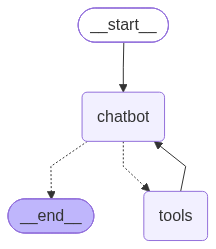

In [7]:
from datetime import date

from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

SYSTEM_PROMPT = SystemMessage(content=(
    f"You are a helpful assistant. Today's date is {date.today()}. "
    "Use the search tool for anything recent or that you are unsure about. "
    "Keep answers short and mention the sources (URLs) you used."
))


def chatbot(state: MessagesState):
    reply = llm_with_tools.invoke([SYSTEM_PROMPT] + state["messages"])
    return {"messages": [reply]}


builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)  # → "tools" or END
builder.add_edge("tools", "chatbot")                       # loop back after the tool runs

agent = builder.compile()

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [8]:
result = agent.invoke({"messages": [HumanMessage(content="What is the price of bitcoin today?")]})

# Look at every step: human → AI (tool call) → tool result → AI (final answer)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the price of bitcoin today?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (b7bz5hy3c)
 Call ID: b7bz5hy3c
  Args:
    query: bitcoin price today
    time_range: day
    topic: finance
================================= Tool Message =================================
Name: tavily_search

{"query": "bitcoin price today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.coinlore.com/coin/bitcoin", "title": "Bitcoin Price, Chart, Market Cap, BTC Coin Essentials | CoinLore", "content": "1. Payments : #1\n2. Layer 1 (L1) : #1\n3. Mineable Coins : #1\n\n## Bitcoin price analysis for today\n\nToday, Bitcoin (BTC) opened at $81,454. It's down by -0.39% from the opening price. Despite rallying to the $82,247 level, Bitcoin (BTC) faced resistance and was unable to maintain the momentum to move higher. From

### Watching each step with `stream`

`stream_mode="updates"` shows what each node returns as it runs. Useful for understanding and debugging the loop.

In [9]:
question = "Who won the most recent Ballon d'Or, and what's one fun fact about them?"

for step in agent.stream({"messages": [HumanMessage(content=question)]}, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"\n===== node: {node_name} =====")
        update["messages"][-1].pretty_print()


===== node: chatbot =====
================================== Ai Message ==================================
Tool Calls:
  tavily_search (snz51rn3m)
 Call ID: snz51rn3m
  Args:
    query: most recent Ballon d'Or winner 2025
    time_range: None

===== node: tools =====
================================= Tool Message =================================
Name: tavily_search

{"query": "most recent Ballon d'Or winner 2025", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://en.wikipedia.org/wiki/Ballon_d%27Or", "title": "Ballon d'Or", "content": "21.   Jump up to: 1234Mikkelsen, Sebastian; Schwager-Patel, Nischal (24 September 2025). \"Football: Ballon d'Or – Complete list of winners including Lionel Messi, Cristiano Ronaldo and Alexia Putellas\". International Olympic Committee. Archived from the original on 26 September 2025. Retrieved 26 September 2025. [...] | _Previous: 69th Ballon d'Or_ 22 September 2025(2025-09-22) _Next: 70th Ballon d'Or_ 26 October

## 7. Memory + interactive chat

Same as notebook 01: compile with a checkpointer and use a `thread_id`.
Now follow-up questions work too ("and what about yesterday?").

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver

agent = builder.compile(checkpointer=InMemorySaver())


def chat(thread_id: str = "search-chat-1"):
    config = {"configurable": {"thread_id": thread_id}}
    print("Search chat started. Type 'quit' to stop.\n")
    while True:
        user_input = input("You: ")
        if user_input.strip().lower() in {"quit", "exit", "q"}:
            print("Goodbye! 👋")
            break
        for step in agent.stream(
            {"messages": [HumanMessage(content=user_input)]}, config, stream_mode="updates"
        ):
            for node_name, update in step.items():
                msg = update["messages"][-1]
                if node_name == "tools":
                    print(f"   🔎 used {msg.name}")
                elif msg.content:
                    print("Bot:", msg.content, "\n")


chat()

Search chat started. Type 'quit' to stop.



## Recap

- A **tool** = function + name + description + argument schema. The docstring matters: the model reads it.
- `llm.bind_tools(tools)` → the model can reply with `tool_calls` instead of text.
- `ToolNode` runs the tool calls; `tools_condition` routes to `tools` or `END`.
- The **`tools → chatbot` edge** makes it a loop, so the model can search several times before answering.

### Try it yourself
1. Give the agent **both** tools: `tools = [tavily_search, duckduckgo_search]` (re-run cells 5–6). Ask which one it picked.
2. Change `TavilySearch(topic="news")` and ask about today's headlines.
3. Write a new `@tool`, e.g. `def calculator(expression: str) -> str` or a weather tool, and add it to `tools`.
4. Remove the date from the system prompt and ask "what happened today?". What goes wrong?

Whats the weather today in lahore?